<img src="https://upload.wikimedia.org/wikipedia/commons/6/6c/Javeriana.svg" width="220">

**Gestión de Datos · Parcial final · Parte 2 (práctica en Kiro)**  
MSc. Edison Leonardo Neira Espitia

**Nombre:** Juan Camilo Guerrero Martínez

**Código:** 1000372165

**Modelo usados:** Claude Opus 5.5 medium.

> Reglas: todo número debe salir de una celda ejecutada. Cada decisión se justifica en una celda markdown escrita por ti. Registra cada prompt en `BITACORA.md`.

## 1. Proyecto y carga (5 pts · 5 min)
1. Crea `.kiro/steering/parcial.md` con al menos 4 reglas tuyas.
2. Carga `data/ConsumerComplaints_taller.csv`. Muestra `shape`, tipos de dato y 5 filas.

In [1]:
# 1.2 Carga del conjunto de datos
# Ruta relativa a la carpeta de trabajo del contenedor (/home/jovyan/work).
# Se carga sin index_col para conservar las 19 columnas originales del archivo.
import numpy as np
import pandas as pd

RUTA_DATOS = "data/ConsumerComplaints_taller.csv"
df = pd.read_csv(RUTA_DATOS)

# La primera columna llega sin encabezado (pandas la nombra 'Unnamed: 0') y es el
# identificador de cada fila del archivo; se renombra a 'ID' para que sea legible.
df = df.rename(columns={"Unnamed: 0": "ID"})

# Dimensiones del dataset: (filas, columnas)
print("Shape:", df.shape)

# Tipos de dato con los que pandas almacenó cada columna
print("\nTipos de dato:")
print(df.dtypes.to_string())

# Primeras 5 filas
display(df.head(5))

Shape: (2018, 19)

Tipos de dato:
ID                                int64
Date Received                    object
Product Name                     object
Sub Product                      object
Issue                            object
Sub Issue                        object
Consumer Complaint Narrative    float64
Company Public Response         float64
Company                          object
State Name                       object
Zip Code                        float64
Tags                             object
Consumer Consent Provided       float64
Submitted via                    object
Date Sent to Company             object
Company Response to Consumer     object
Timely Response                  object
Consumer Disputed                object
Complaint ID                      int64


,ID,Date Received,Product Name,Sub Product,Issue,Sub Issue,Consumer Complaint Narrative,Company Public Response,Company,State Name,Zip Code,Tags,Consumer Consent Provided,Submitted via,Date Sent to Company,Company Response to Consumer,Timely Response,Consumer Disputed,Complaint ID
0,0,2013-07-29,Consumer Loan,Vehicle loan,Managing the loan or lease,NaN,1.959499,-1.005918,Wells Fargo & Company,VA,24540.0,NaN,47.230318,Phone,2013-07-30,Closed with explanation,Yes,No,468882
1,1,2013-07-29,Bank account or service,Checking account,Using a debit or ATM card,NaN,3.088140,-1.627802,Wells Fargo & Company,CA,95992.0,Older American,94.123629,Web,2013-07-31,Closed with explanation,Yes,No,468889
2,2,2013-07-29,Bank account or service,Checking account,"Account opening, closing, or management",NaN,1.540415,-0.517982,Santander Bank US,NY,10065.0,NaN,54.797696,Fax,2013-07-31,Closed,Yes,No,468879
3,3,2013-07-29,Bank account or service,Checking account,Deposits and withdrawals,NaN,0.529138,-1.684442,Wells Fargo & Company,GA,30084.0,NaN,24.592621,Web,2013-07-30,Closed with explanation,Yes,No,468949
4,4,2013-07-29,Mortgage,Conventional fixed mortgage,"Loan servicing, payments, escrow account",NaN,0.807998,-1.422837,Franklin Credit Management,CT,6106.0,NaN,34.089013,Web,2013-07-30,Closed with explanation,Yes,No,475823


## 2. Perfilado y tipos de variable (8 pts · 10 min)
1. Tabla con las 19 columnas: tipo de almacenamiento, tipo conceptual (nominal, ordinal, discreta, continua, fecha o identificador), nulos (cantidad y %) y valores distintos.
2. ¿Cuántas columnas son categóricas y cuántas numéricas según el almacenamiento? ¿Y según el tipo conceptual?
3. Identifica al menos 2 columnas cuyo tipo de almacenamiento no corresponde a su tipo conceptual y explica por qué.

In [2]:
# 2.1 Tabla de perfilado de las 19 columnas
# El tipo conceptual se asigna manualmente según el significado de cada columna
# (no según cómo la almacenó pandas). Criterios:
#   - identificador: valor único por fila que no aporta información analítica.
#   - fecha: representa un instante en el tiempo.
#   - nominal: categorías sin orden natural (incluye códigos como Zip Code y binarias Yes/No).
#   - ordinal: categorías con orden natural.
#   - discreta / continua: cantidades numéricas contables / medibles.
tipo_conceptual = {
    "ID": "identificador",
    "Date Received": "fecha",
    "Product Name": "nominal",
    "Sub Product": "nominal",
    "Issue": "nominal",
    "Sub Issue": "nominal",
    "Consumer Complaint Narrative": "continua",
    "Company Public Response": "continua",
    "Company": "nominal",
    "State Name": "nominal",
    "Zip Code": "nominal",
    "Tags": "nominal",
    "Consumer Consent Provided": "continua",
    "Submitted via": "nominal",
    "Date Sent to Company": "fecha",
    "Company Response to Consumer": "nominal",
    "Timely Response": "nominal",
    "Consumer Disputed": "nominal",
    "Complaint ID": "identificador",
}

# Control: el diccionario debe cubrir exactamente las columnas del DataFrame
assert set(tipo_conceptual) == set(df.columns), "Faltan o sobran columnas en tipo_conceptual"

# Agrupación de los tipos en categórica / numérica / otro para las preguntas 2.2 y 2.3
grupo_conceptual = {
    "nominal": "categórica", "ordinal": "categórica",
    "discreta": "numérica", "continua": "numérica",
    "fecha": "fecha", "identificador": "identificador",
}

perfil = pd.DataFrame({
    "tipo_almacenamiento": df.dtypes.astype(str),
    "tipo_conceptual": pd.Series(tipo_conceptual),
    "nulos": df.isna().sum(),
    "nulos_%": (df.isna().mean() * 100).round(2),
    "valores_distintos": df.nunique(),
})
# Según el almacenamiento: object -> categórica; int/float -> numérica
perfil["grupo_almacenamiento"] = perfil["tipo_almacenamiento"].map(
    lambda t: "numérica" if t.startswith(("int", "float")) else "categórica"
)
perfil["grupo_conceptual"] = perfil["tipo_conceptual"].map(grupo_conceptual)
perfil["coincide"] = perfil["grupo_almacenamiento"] == perfil["grupo_conceptual"]
perfil.index.name = "columna"

print("Número de columnas perfiladas:", len(perfil))
display(perfil)

# 2.2 Conteo de columnas categóricas y numéricas
print("\n2.2 Según el tipo de almacenamiento:")
print(perfil["grupo_almacenamiento"].value_counts().to_string())

print("\n2.2 Según el tipo conceptual (detalle):")
print(perfil["tipo_conceptual"].value_counts().to_string())

print("\n2.2 Según el tipo conceptual (agrupado):")
print(perfil["grupo_conceptual"].value_counts().to_string())

# 2.3 Columnas cuyo tipo de almacenamiento no corresponde a su tipo conceptual
print("\n2.3 Columnas con almacenamiento distinto al tipo conceptual:")
display(perfil.loc[~perfil["coincide"], ["tipo_almacenamiento", "tipo_conceptual", "valores_distintos"]])

# Evidencia para 2.3: Zip Code se guarda como float aunque todos sus valores son enteros
# (códigos postales), y las fechas se guardan como texto (object)
zip_no_nulos = df["Zip Code"].dropna()
print("Zip Code: ¿todos los valores no nulos son enteros? ->", bool((zip_no_nulos % 1 == 0).all()))
print("Ejemplo de fechas guardadas como texto:", df["Date Received"].iloc[0], "| tipo Python:", type(df["Date Received"].iloc[0]).__name__)

Número de columnas perfiladas: 19


,tipo_almacenamiento,tipo_conceptual,nulos,nulos_%,valores_distintos,grupo_almacenamiento,grupo_conceptual,coincide
columna,,,,,,,,
ID,int64,identificador,0,0.00,2018,numérica,identificador,False
Date Received,object,fecha,0,0.00,29,categórica,fecha,False
Product Name,object,nominal,0,0.00,8,categórica,categórica,True
Sub Product,object,nominal,483,23.93,26,categórica,categórica,True
Issue,object,nominal,0,0.00,63,categórica,categórica,True
Sub Issue,object,nominal,1462,72.45,45,categórica,categórica,True
Consumer Complaint Narrative,float64,continua,0,0.00,2018,numérica,numérica,True
Company Public Response,float64,continua,0,0.00,2018,numérica,numérica,True
Company,object,nominal,0,0.00,234,categórica,categórica,True



2.2 Según el tipo de almacenamiento:
grupo_almacenamiento
categórica    13
numérica       6

2.2 Según el tipo conceptual (detalle):
tipo_conceptual
nominal          12
continua          3
fecha             2
identificador     2

2.2 Según el tipo conceptual (agrupado):
grupo_conceptual
categórica       12
numérica          3
fecha             2
identificador     2

2.3 Columnas con almacenamiento distinto al tipo conceptual:


,tipo_almacenamiento,tipo_conceptual,valores_distintos
columna,,,
ID,int64,identificador,2018
Date Received,object,fecha,29
Zip Code,float64,nominal,1685
Date Sent to Company,object,fecha,74
Complaint ID,int64,identificador,2018


Zip Code: ¿todos los valores no nulos son enteros? -> True
Ejemplo de fechas guardadas como texto: 2013-07-29 | tipo Python: str


**Respuesta 2.2 y 2.3:**

**2.2 Columnas categóricas y numéricas**

| Criterio | Categóricas | Numéricas | Fecha | Identificador | Total |
|---|---|---|---|---|---|
| Tipo de almacenamiento | 13 (`object`) | 6 (`int64` / `float64`) | — | — | 19 |
| Tipo conceptual | 12 (nominales) | 3 (continuas) | 2 | 2 | 19 |

Según el **almacenamiento**, pandas guarda como numéricas 6 columnas: `ID`, `Complaint ID`, `Consumer Complaint Narrative`, `Company Public Response`, `Zip Code` y `Consumer Consent Provided`; las otras 13 quedan como texto (`object`). Según el **tipo conceptual**, solo 3 son realmente numéricas (las continuas `Consumer Complaint Narrative`, `Company Public Response` y `Consumer Consent Provided`) y 12 son categóricas nominales; las 4 restantes no son ni lo uno ni lo otro: 2 fechas (`Date Received`, `Date Sent to Company`) y 2 identificadores (`ID`, `Complaint ID`). No hay variables ordinales ni discretas.

**2.3 Columnas cuyo almacenamiento no corresponde a su tipo conceptual**

La tabla del punto 2.1 marca 5 columnas con `coincide = False`:

- **`Zip Code`** (`float64` → nominal): es un código postal, no una cantidad; sumarlo o promediarlo no tiene sentido, y sus 1685 valores distintos son etiquetas de ubicación. Además, todos sus valores no nulos son enteros (verificado en la celda), y se guarda como `float` solo porque tiene 11 nulos; esto también altera el código: por ejemplo, el de Connecticut aparece como `6106.0` en lugar de `06106`.
- **`Date Received` y `Date Sent to Company`** (`object` → fecha): se guardan como texto (por ejemplo `'2013-07-29'`, tipo `str`), así que no se pueden ordenar cronológicamente de forma fiable ni restar para calcular días entre fechas; por eso en el punto 4.3 se convierten a `datetime`.
- **`ID` y `Complaint ID`** (`int64` → identificador): aunque son números, cada uno tiene 2018 valores distintos en 2018 filas; solo identifican cada registro y no miden nada, por lo que calcular estadísticas sobre ellos (media, correlación) carece de significado.


## 3. Estadística descriptiva (8 pts · 10 min)
1. Para las 3 columnas numéricas continuas: Q1, Q2, Q3, IQR, media, mediana, sesgo y curtosis de Fisher en una tabla.
2. Interpreta el sesgo y la curtosis de cada una.
3. Histograma con KDE de las 3 y un boxplot de una de ellas por `Product Name`. Escribe una observación por gráfico.

Columnas continuas: ['Consumer Complaint Narrative', 'Company Public Response', 'Consumer Consent Provided']


,Q1,Q2,Q3,IQR,media,mediana,sesgo,curtosis_fisher
columna,,,,,,,,
Consumer Complaint Narrative,0.7789,1.1868,1.8965,1.1177,1.5058,1.1868,2.1705,8.1486
Company Public Response,-1.8354,-1.1559,-0.7777,1.0577,-1.4669,-1.1559,-1.9252,4.6870
Consumer Consent Provided,25.7541,49.0352,75.1251,49.3710,50.0441,49.0352,0.0365,-1.1564


,sesgo,forma_sesgo,curtosis_fisher,forma_curtosis,media_menos_mediana
columna,,,,,
Consumer Complaint Narrative,2.1705,sesgo alto positivo (cola a la derecha),8.1486,leptocúrtica,0.3191
Company Public Response,-1.9252,sesgo alto negativo (cola a la izquierda),4.6870,leptocúrtica,-0.3110
Consumer Consent Provided,0.0365,aprox. simétrica,-1.1564,platicúrtica,1.0090


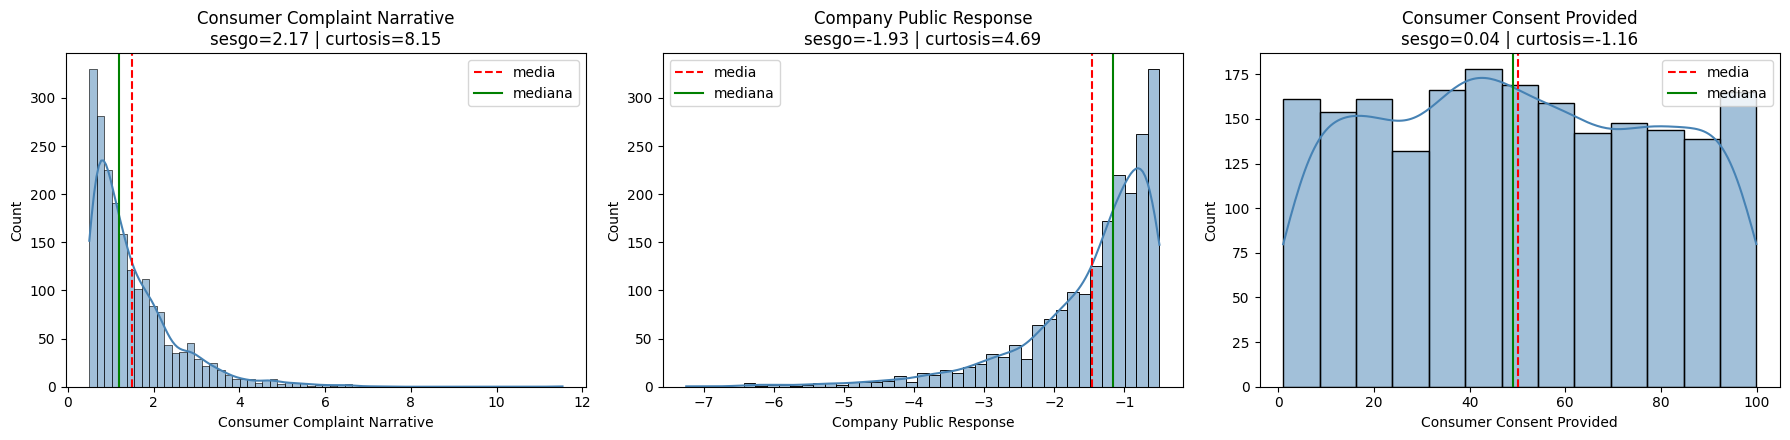

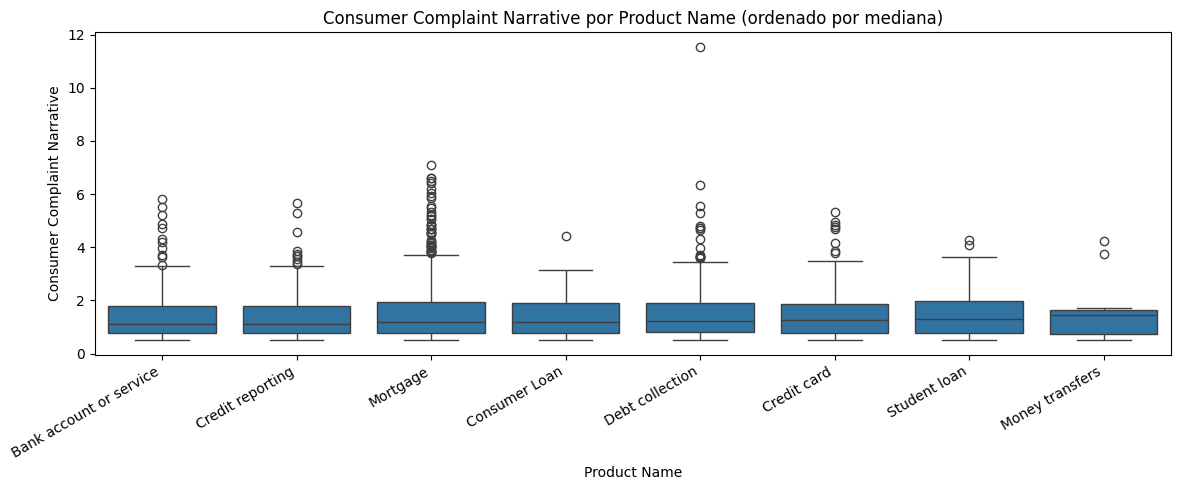

,count,25%,50%,75%,max
Product Name,,,,,
Bank account or service,256.0,0.7798,1.1023,1.7930,5.8210
Credit reporting,241.0,0.7696,1.1260,1.8042,5.6719
Mortgage,905.0,0.7786,1.1937,1.9457,7.1115
Consumer Loan,48.0,0.7797,1.1990,1.9075,4.4369
Debt collection,267.0,0.8144,1.2270,1.8837,11.5381
Credit card,242.0,0.7712,1.2449,1.8797,5.3263
Student loan,48.0,0.7878,1.3101,1.9736,4.2597
Money transfers,11.0,0.7319,1.4327,1.6419,4.2356


In [3]:
# 3. Estadística descriptiva de las 3 columnas numéricas continuas
import matplotlib.pyplot as plt
import seaborn as sns

# Se toman directamente de la tabla de perfilado del punto 2 (tipo conceptual = continua)
cols_continuas = perfil.index[perfil["tipo_conceptual"] == "continua"].tolist()
print("Columnas continuas:", cols_continuas)

# 3.1 Tabla de indicadores
# Sesgo y curtosis con pandas: estimadores insesgados de la muestra; .kurt() devuelve la
# curtosis de Fisher (exceso), es decir, la normal tiene curtosis 0.
q = df[cols_continuas].quantile([0.25, 0.50, 0.75])
estadisticos = pd.DataFrame({
    "Q1": q.loc[0.25],
    "Q2": q.loc[0.50],
    "Q3": q.loc[0.75],
    "IQR": q.loc[0.75] - q.loc[0.25],
    "media": df[cols_continuas].mean(),
    "mediana": df[cols_continuas].median(),
    "sesgo": df[cols_continuas].skew(),
    "curtosis_fisher": df[cols_continuas].kurt(),
})
display(estadisticos.round(4))

# 3.2 Apoyo para la interpretación: clasificación según umbrales usuales
#   Sesgo: |s| < 0.5 aprox. simétrica; 0.5–1 moderado; > 1 alto (signo = dirección de la cola).
#   Curtosis de Fisher: > 0.5 leptocúrtica (colas pesadas); < -0.5 platicúrtica (colas ligeras);
#   entre -0.5 y 0.5 mesocúrtica (similar a la normal).
def clasificar_sesgo(s):
    if abs(s) < 0.5:
        return "aprox. simétrica"
    nivel = "moderado" if abs(s) <= 1 else "alto"
    direccion = "positivo (cola a la derecha)" if s > 0 else "negativo (cola a la izquierda)"
    return f"sesgo {nivel} {direccion}"

def clasificar_curtosis(k):
    if k > 0.5:
        return "leptocúrtica"
    if k < -0.5:
        return "platicúrtica"
    return "mesocúrtica"

interpretacion = pd.DataFrame({
    "sesgo": estadisticos["sesgo"].round(4),
    "forma_sesgo": estadisticos["sesgo"].map(clasificar_sesgo),
    "curtosis_fisher": estadisticos["curtosis_fisher"].round(4),
    "forma_curtosis": estadisticos["curtosis_fisher"].map(clasificar_curtosis),
    "media_menos_mediana": (estadisticos["media"] - estadisticos["mediana"]).round(4),
})
display(interpretacion)

# 3.3 Histogramas con KDE de las 3 variables
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, cols_continuas):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.axvline(estadisticos.loc[col, "media"], color="red", linestyle="--", label="media")
    ax.axvline(estadisticos.loc[col, "mediana"], color="green", linestyle="-", label="mediana")
    ax.set_title(f"{col}\nsesgo={estadisticos.loc[col, 'sesgo']:.2f} | curtosis={estadisticos.loc[col, 'curtosis_fisher']:.2f}")
    ax.legend()
plt.tight_layout()
plt.show()

# 3.3 Boxplot por Product Name
# Se elige la variable con mayor sesgo absoluto, donde los atípicos son más visibles.
col_box = estadisticos["sesgo"].abs().idxmax()
orden_productos = df.groupby("Product Name")[col_box].median().sort_values().index
plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x="Product Name", y=col_box, order=orden_productos)
plt.title(f"{col_box} por Product Name (ordenado por mediana)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Resumen numérico por producto que respalda la observación del boxplot
display(
    df.groupby("Product Name")[col_box]
      .describe()[["count", "25%", "50%", "75%", "max"]]
      .loc[orden_productos]
      .round(4)
)

**Interpretación:**

*Criterios usados (ver celda anterior):* sesgo |s| < 0.5 ≈ simétrica, 0.5–1 moderado, > 1 alto; curtosis de Fisher > 0.5 leptocúrtica, < −0.5 platicúrtica, intermedia mesocúrtica (la normal vale 0).

**3.2 Sesgo y curtosis**

| Variable | Sesgo | Curtosis (Fisher) | Lectura |
|---|---|---|---|
| `Consumer Complaint Narrative` | 2.1705 | 8.1486 | Sesgo **alto positivo**: la mayoría de valores se concentra cerca del mínimo y hay una cola larga hacia la derecha; por eso la media (1.5058) supera a la mediana (1.1868) en 0.3191. Curtosis muy por encima de 0 → **leptocúrtica**: colas pesadas, es decir, más valores extremos de los que tendría una normal. |
| `Company Public Response` | −1.9252 | 4.6870 | Sesgo **alto negativo**: es el espejo de la anterior, con los valores acumulados cerca del máximo y una cola larga hacia valores más negativos; la media (−1.4669) queda por debajo de la mediana (−1.1559) en 0.3110. **Leptocúrtica**: colas pesadas y presencia de valores extremos en el lado izquierdo. |
| `Consumer Consent Provided` | 0.0365 | −1.1564 | **Aproximadamente simétrica**: media (50.0441) y mediana (49.0352) casi coinciden y Q2 queda prácticamente en el centro entre Q1 (25.7541) y Q3 (75.1251). **Platicúrtica**: distribución aplanada y sin colas; el valor está cerca de −1.2, que es la curtosis de Fisher de una distribución uniforme, lo que sugiere que los valores se reparten de forma casi homogénea. |

*Implicación para los puntos siguientes:* las dos primeras variables tienen colas pesadas y asimetría fuerte, por lo que son candidatas a revisión de atípicos (4.4) y a transformaciones o escalamientos robustos (5.1); en ellas la mediana y el IQR describen mejor el centro y la dispersión que la media. `Consumer Consent Provided` no presenta ese problema.

**3.3 Observaciones de los gráficos**

- **Histograma de `Consumer Complaint Narrative`:** el pico está a la izquierda, cerca del mínimo, y la densidad decae lentamente hacia la derecha; la línea de la media queda a la derecha de la mediana, lo que confirma el sesgo positivo.
- **Histograma de `Company Public Response`:** el pico está pegado al extremo derecho y la cola se extiende hacia valores negativos; la media queda a la izquierda de la mediana, coherente con el sesgo negativo.
- **Histograma de `Consumer Consent Provided`:** las barras tienen alturas similares en todo el rango y la KDE es casi plana, sin un pico marcado; media y mediana prácticamente se superponen.
- **Boxplot de `Consumer Complaint Narrative` por `Product Name`:** las medianas por producto son muy parecidas (entre 1.1023 en *Bank account or service* y 1.4327 en *Money transfers*), así que el producto no parece desplazar el centro de la variable. Todos los productos muestran atípicos por encima del bigote superior, lo que indica que la asimetría es propia de la variable y no de un producto en particular. *Mortgage* concentra la mayor cantidad de puntos atípicos (también es el producto con más quejas, 905) y el valor más extremo (11.5381) está en *Debt collection*. *Money transfers* tiene solo 11 registros, por lo que su caja es poco confiable.

## 4. Limpieza (14 pts · 20 min)
Justifica cada decisión en markdown.

### 4.1 Atributos sin valor
Identificadores, columnas con muy alta proporción de nulos y duplicados (exactos y por identificador).

In [4]:
# 4.1 Atributos sin valor
# Se trabaja sobre una copia para conservar el DataFrame original (df) intacto.
df_limpio = df.copy()
print("Shape inicial:", df_limpio.shape)

# --- a) Identificadores ---------------------------------------------------------------
# Columnas marcadas como identificador en el perfilado del punto 2.
cols_id = perfil.index[perfil["tipo_conceptual"] == "identificador"].tolist()
print("\na) Columnas identificador:", cols_id)
display(pd.DataFrame({
    "valores_distintos": df_limpio[cols_id].nunique(),
    "filas": len(df_limpio),
    "unico_por_fila": df_limpio[cols_id].nunique() == len(df_limpio),
}))
# 'ID' es solo la posición de la fila en el archivo exportado (0, 1, 2, ..., n-1)
print("¿ID coincide con la posición de la fila (0..n-1)?",
      bool((df_limpio["ID"].values == range(len(df_limpio))).all()))

# --- b) Columnas con muy alta proporción de nulos ---------------------------------------
# Umbral: más del 80 % de nulos. Por encima de ese nivel la columna casi no tiene
# información observada y cualquier imputación inventaría la mayoría de los valores.
UMBRAL_NULOS = 80
nulos_pct = (df_limpio.isna().mean() * 100).round(2).sort_values(ascending=False)
print(f"\nb) Porcentaje de nulos por columna (umbral = {UMBRAL_NULOS} %):")
display(nulos_pct[nulos_pct > 0].to_frame("nulos_%"))
cols_muchos_nulos = nulos_pct[nulos_pct > UMBRAL_NULOS].index.tolist()
print("Columnas por encima del umbral:", cols_muchos_nulos)
print("Valores observados de Tags (incluye NaN):")
print(df_limpio["Tags"].value_counts(dropna=False).to_string())

# --- c) Duplicados ----------------------------------------------------------------------
# Exactos con todas las columnas: 'ID' es distinto en cada fila, así que también se
# revisa sin los identificadores para detectar quejas repetidas con distinto ID.
dup_exactos = df_limpio.duplicated().sum()
dup_sin_ids = df_limpio.drop(columns=cols_id).duplicated().sum()
# Por identificador de negocio: una misma queja (Complaint ID) no debería repetirse.
dup_complaint_id = df_limpio["Complaint ID"].duplicated().sum()
print("\nc) Duplicados")
print("Exactos (todas las columnas):          ", dup_exactos)
print("Exactos (sin columnas identificador):  ", dup_sin_ids)
print("Por identificador (Complaint ID):      ", dup_complaint_id)

# Se eliminan duplicados solo si existen (primero exactos, luego por Complaint ID)
df_limpio = df_limpio.drop_duplicates()
df_limpio = df_limpio.drop_duplicates(subset=df_limpio.columns.difference(cols_id))
df_limpio = df_limpio.drop_duplicates(subset="Complaint ID")
print("Filas después de tratar duplicados:", len(df_limpio))

# --- Aplicación de la decisión -----------------------------------------------------------
# Se eliminan los identificadores (ya usados para verificar duplicados) y las columnas
# con nulos por encima del umbral.
cols_eliminar = cols_id + cols_muchos_nulos
df_limpio = df_limpio.drop(columns=cols_eliminar)
print("\nColumnas eliminadas:", cols_eliminar)
print("Shape después de 4.1:", df_limpio.shape)

Shape inicial: (2018, 19)

a) Columnas identificador: ['ID', 'Complaint ID']


,valores_distintos,filas,unico_por_fila
columna,,,
ID,2018,2018,True
Complaint ID,2018,2018,True


¿ID coincide con la posición de la fila (0..n-1)? True

b) Porcentaje de nulos por columna (umbral = 80 %):


,nulos_%
columna,
Tags,85.48
Sub Issue,72.45
Sub Product,23.93
Consumer Disputed,0.89
State Name,0.55
Zip Code,0.55


Columnas por encima del umbral: ['Tags']
Valores observados de Tags (incluye NaN):
Tags
NaN                              1725
Older American                    183
Servicemember                      89
Older American, Servicemember      21

c) Duplicados
Exactos (todas las columnas):           0
Exactos (sin columnas identificador):   0
Por identificador (Complaint ID):       0
Filas después de tratar duplicados: 2018

Columnas eliminadas: ['ID', 'Complaint ID', 'Tags']
Shape después de 4.1: (2018, 16)


**Decisión y justificación:**

Se eliminaron las columnas `ID` y `Complaint ID` porque son identificadores: cada una tiene 2018 valores distintos en 2018 filas (un valor único por registro) y `ID` coincide exactamente con la posición de la fila (0..n-1), por lo que no describen ninguna característica de la queja y no aportan valor al análisis ni al modelo; antes de retirarlas se usaron para verificar duplicados, y no se encontraron duplicados exactos (0, con y sin identificadores) ni por `Complaint ID` (0). También se eliminó `Tags` por superar el umbral de 80 % de nulos (85.48 %). `Sub Issue` (72.45 %) se conserva porque se trata en el punto 4.2. El dataset pasa de (2018, 19) a (2018, 16).

### 4.2 Faltantes
Para `Sub Product`, `Sub Issue`, `State Name`/`Zip Code` y `Consumer Disputed`: cuantifica, identifica el mecanismo (MCAR, MAR o MNAR) cruzando con al menos otra variable (Cuando se justifique el caso) y aplica un tratamiento justificado.

In [5]:
# 4.2 Faltantes: cuantificación, mecanismo (cruce con otras variables) y tratamiento
from scipy.stats import chi2_contingency

cols_faltantes = ["Sub Product", "Sub Issue", "State Name", "Zip Code", "Consumer Disputed"]

# --- a) Cuantificación ---------------------------------------------------------------------
print("Shape de partida (salida de 4.1):", df_limpio.shape)
cuantificacion = pd.DataFrame({
    "nulos": df_limpio[cols_faltantes].isna().sum(),
    "nulos_%": (df_limpio[cols_faltantes].isna().mean() * 100).round(2),
})
display(cuantificacion)

# Función auxiliar: % de nulos de una columna dentro de cada categoría de otra variable
def pct_nulos_por(col, por):
    return (df_limpio.groupby(por)[col]
            .agg(nulos=lambda s: s.isna().sum(), total="size", pct_nulos=lambda s: round(s.isna().mean() * 100, 2)))

# Función auxiliar: chi-cuadrado de independencia entre "col es nulo" y otra variable.
# Reporta también el % de celdas con frecuencia esperada < 5 (si supera el 20 %, la
# aproximación chi-cuadrado no es confiable).
def chi2_nulos(col, var):
    tabla = pd.crosstab(df_limpio[var], df_limpio[col].isna())
    chi2, p, gl, esperadas = chi2_contingency(tabla)
    pct_bajas = (esperadas < 5).mean() * 100
    print(f"  '{col}' nulo vs {var:<28} chi2 = {chi2:9.4f} | gl = {gl} | p-valor = {p:.3e} "
          f"| celdas esperadas < 5: {pct_bajas:.1f} %")

# --- b) Sub Product y Sub Issue vs Product Name ---------------------------------------------
# Si los nulos dependen del producto (0 % o 100 % por categoría), el faltante es estructural:
# ese producto no tiene subcategoría definida.
print("\nb.1) % de nulos de Sub Product por Product Name")
display(pct_nulos_por("Sub Product", "Product Name"))
print("b.2) % de nulos de Sub Issue por Product Name")
display(pct_nulos_por("Sub Issue", "Product Name"))

# Verificación: ¿algún producto tiene nulos parciales (ni 0 % ni 100 %)?
for col in ["Sub Product", "Sub Issue"]:
    pct = df_limpio.groupby("Product Name")[col].apply(lambda s: s.isna().mean())
    parciales = pct[(pct > 0) & (pct < 1)]
    print(f"{col}: productos con nulos parciales -> {len(parciales)}")

# --- c) State Name / Zip Code ---------------------------------------------------------------
# ¿Faltan siempre juntos?
print("\nc.1) Coincidencia de nulos entre State Name y Zip Code")
display(pd.crosstab(df_limpio["State Name"].isna(), df_limpio["Zip Code"].isna(),
                    rownames=["State Name nulo"], colnames=["Zip Code nulo"]))

# ¿Dependen de alguna variable observada?
print("c.2) Independencia entre 'State Name nulo' y otras variables (chi-cuadrado)")
for var in ["Product Name", "Submitted via", "Consumer Disputed"]:
    chi2_nulos("State Name", var)
print("\nc.3) % de nulos de State Name por Product Name y por Submitted via")
display(pct_nulos_por("State Name", "Product Name"))
display(pct_nulos_por("State Name", "Submitted via"))

# Prueba de sensibilidad: se repite el chi-cuadrado excluyendo categorías con menos de 30
# registros, para ver si la dependencia se sostiene sin los grupos diminutos.
MIN_REGISTROS = 30
print(f"c.4) Chi-cuadrado excluyendo categorías con menos de {MIN_REGISTROS} registros")
for var in ["Product Name", "Submitted via"]:
    conteo = df_limpio[var].value_counts()
    excluidas = conteo[conteo < MIN_REGISTROS]
    sub = df_limpio[df_limpio[var].isin(conteo[conteo >= MIN_REGISTROS].index)]
    tabla = pd.crosstab(sub[var], sub["State Name"].isna())
    chi2, p, gl, esperadas = chi2_contingency(tabla)
    print(f"  vs {var:<14} excluidas = {excluidas.to_dict()} | chi2 = {chi2:.4f} | gl = {gl} "
          f"| p-valor = {p:.4f} | celdas esperadas < 5: {(esperadas < 5).mean() * 100:.1f} %")

# --- d) Consumer Disputed vs Timely Response y Company Response ------------------------------
print("\nd.1) % de nulos de Consumer Disputed por Timely Response")
display(pct_nulos_por("Consumer Disputed", "Timely Response"))
print("d.2) % de nulos de Consumer Disputed por Company Response to Consumer")
display(pct_nulos_por("Consumer Disputed", "Company Response to Consumer"))
chi2_nulos("Consumer Disputed", "Timely Response")

# --- e) Tratamiento --------------------------------------------------------------------------
filas_antes = len(df_limpio)

# Sub Product / Sub Issue: faltante estructural -> categoría explícita "No aplica"
for col in ["Sub Product", "Sub Issue"]:
    df_limpio[col] = df_limpio[col].fillna("No aplica")

# State Name / Zip Code: faltan en las mismas filas y son pocas -> eliminación de filas
n_geo = df_limpio["State Name"].isna().sum()
df_limpio = df_limpio.dropna(subset=["State Name", "Zip Code"])

# Consumer Disputed: es la variable objetivo; no se imputa para no inventar etiquetas
n_obj = df_limpio["Consumer Disputed"].isna().sum()
df_limpio = df_limpio.dropna(subset=["Consumer Disputed"])

print("\ne) Tratamiento aplicado")
print("Filas eliminadas por State Name/Zip Code nulos:", n_geo)
print("Filas eliminadas por Consumer Disputed nulo:   ", n_obj)
print(f"Filas: {filas_antes} -> {len(df_limpio)} ({filas_antes - len(df_limpio)} eliminadas, "
      f"{(filas_antes - len(df_limpio)) / filas_antes * 100:.2f} %)")
print("\nNulos restantes en las columnas tratadas:")
print(df_limpio[cols_faltantes].isna().sum().to_string())
print("\nEfecto colateral en Timely Response (después del tratamiento):")
print(df_limpio["Timely Response"].value_counts().to_string())
print("\nShape después de 4.2:", df_limpio.shape)

Shape de partida (salida de 4.1): (2018, 16)


,nulos,nulos_%
columna,,
Sub Product,483,23.93
Sub Issue,1462,72.45
State Name,11,0.55
Zip Code,11,0.55
Consumer Disputed,18,0.89



b.1) % de nulos de Sub Product por Product Name


,nulos,total,pct_nulos
Product Name,,,
Bank account or service,0,256,0.0
Consumer Loan,0,48,0.0
Credit card,242,242,100.0
Credit reporting,241,241,100.0
Debt collection,0,267,0.0
Money transfers,0,11,0.0
Mortgage,0,905,0.0
Student loan,0,48,0.0


b.2) % de nulos de Sub Issue por Product Name


,nulos,total,pct_nulos
Product Name,,,
Bank account or service,256,256,100.0
Consumer Loan,48,48,100.0
Credit card,242,242,100.0
Credit reporting,0,241,0.0
Debt collection,0,267,0.0
Money transfers,11,11,100.0
Mortgage,905,905,100.0
Student loan,0,48,0.0


... (6 outputs left out)

,nulos,total,pct_nulos
Timely Response,,,
No,17,24,70.83
Yes,1,1994,0.05


d.2) % de nulos de Consumer Disputed por Company Response to Consumer


,nulos,total,pct_nulos
Company Response to Consumer,,,
Closed,3,67,4.48
Closed with explanation,11,1496,0.74
Closed with monetary relief,0,167,0.00
Closed with non-monetary relief,1,285,0.35
Untimely response,3,3,100.00


  'Consumer Disputed' nulo vs Timely Response              chi2 = 1265.1719 | gl = 1 | p-valor = 4.187e-277 | celdas esperadas < 5: 25.0 %

e) Tratamiento aplicado
Filas eliminadas por State Name/Zip Code nulos: 11
Filas eliminadas por Consumer Disputed nulo:    18
Filas: 2018 -> 1989 (29 eliminadas, 1.44 %)

Nulos restantes en las columnas tratadas:
columna
Sub Product          0
Sub Issue            0
State Name           0
Zip Code             0
Consumer Disputed    0

Efecto colateral en Timely Response (después del tratamiento):
Timely Response
Yes    1982
No        7

Shape después de 4.2: (1989, 16)


**Mecanismo y tratamiento de cada columna:**

| Columna | Nulos | Cruce y evidencia | Mecanismo | Tratamiento |
|---|---|---|---|---|
| `Sub Product` | 483 (23.93 %) | Por `Product Name`, los nulos son 100 % en *Credit card* (242/242) y *Credit reporting* (241/241) y 0 % en el resto; ningún producto tiene nulos parciales. | **MAR** (estructural): la ausencia depende por completo de una variable observada; esos productos no tienen subproducto definido. | Imputar la categoría **"No aplica"**. No es un dato perdido sino una categoría inexistente, así que imputar la moda inventaría información. |
| `Sub Issue` | 1462 (72.45 %) | Por `Product Name`, 100 % de nulos en *Bank account or service*, *Consumer Loan*, *Credit card*, *Money transfers* y *Mortgage*; 0 % en *Credit reporting*, *Debt collection* y *Student loan*; ningún producto tiene nulos parciales. | **MAR** (estructural), mismo patrón que `Sub Product`: solo tres productos usan subtema. | Imputar **"No aplica"**. Por eso se conservó en 4.1 pese a superar el 70 %: la ausencia sí es informativa. |
| `State Name` / `Zip Code` | 11 (0.55 %) cada una | Faltan siempre en las **mismas 11 filas**. No hay relación con la variable objetivo (chi² vs `Consumer Disputed`: p = 0.9856). Con `Product Name` la aparente dependencia (p = 1.174e-03) desaparece al excluir *Money transfers*, de 11 registros (p = 0.1302). Con `Submitted via` persiste (p = 0.0018 sin *Fax* ni *Email*): *Phone* tiene 2.09 % de nulos frente a 0.18 % en *Web*. En las pruebas con `Product Name` y `Submitted via` ≥ 37.5 % de las celdas esperadas son < 5, así que la evidencia es débil. | **MAR débil** (posible relación con el canal telefónico, donde la dirección puede no registrarse); no se puede afirmar MCAR con certeza. | **Eliminar las 11 filas**: son el 0.55 % de los datos, no están asociadas al objetivo, y `Zip Code` (1685 valores distintos) no admite una imputación razonable. |
| `Consumer Disputed` | 18 (0.89 %) | Por `Timely Response`: 70.83 % de nulos cuando es *No* (17/24) frente a 0.05 % cuando es *Yes* (1/1994); chi² = 1265.1719, p = 4.187e-277. Por `Company Response to Consumer`, 100 % de nulos en *Untimely response* (3/3). | **MAR**: la ausencia depende de que la empresa no respondiera a tiempo; sin respuesta oportuna, el consumidor no llega a la etapa de disputa. | **Eliminar las 18 filas**: es la variable objetivo y no se debe imputar una etiqueta. |

**Resultado:** se eliminaron 29 filas (1.44 %) y el dataset pasa de (2018, 16) a **(1989, 16)**, sin nulos en las columnas tratadas.

**Efecto colateral a tener en cuenta:** al eliminar los nulos del objetivo, `Timely Response` queda con 1982 *Yes* y solo 7 *No*, es decir, casi constante; se debe considerar su poca utilidad como predictor en la vista minable (punto 5).

### 4.3 Inconsistencias
Verifica que las fechas sean coherentes (una queja no puede enviarse a la empresa antes de recibirse) y trata los casos encontrados.

In [6]:
# 4.3 Inconsistencias de fechas
# Las fechas llegaron como texto (ver 2.3); se convierten a datetime. errors="coerce"
# convierte en NaT cualquier valor que no sea una fecha válida, para poder contarlos.
for col in ["Date Received", "Date Sent to Company"]:
    df_limpio[col] = pd.to_datetime(df_limpio[col], errors="coerce")
print("Fechas no convertibles (NaT):")
print(df_limpio[["Date Received", "Date Sent to Company"]].isna().sum().to_string())

# Regla de negocio: Date Sent to Company >= Date Received
dias = (df_limpio["Date Sent to Company"] - df_limpio["Date Received"]).dt.days
inconsistentes = dias < 0
print(f"\nRegistros inconsistentes (envío antes de recepción): {inconsistentes.sum()} "
      f"de {len(df_limpio)} ({inconsistentes.mean() * 100:.2f} %)")

# Caracterización de los casos: magnitud del desfase y canal de envío
print("\nDiferencia en días de los casos inconsistentes:")
print(dias[inconsistentes].value_counts().sort_index().to_string())
print("\nCanal (Submitted via) de los casos inconsistentes vs. total:")
display(pd.DataFrame({
    "inconsistentes": df_limpio.loc[inconsistentes, "Submitted via"].value_counts(),
    "total": df_limpio["Submitted via"].value_counts(),
}).fillna(0).astype(int))
display(df_limpio.loc[inconsistentes, ["Date Received", "Date Sent to Company", "Submitted via"]].head())

# Tratamiento: el desfase es siempre de 1 día y solo ocurre en quejas por Web, lo que
# apunta a un error sistemático de registro (p. ej. zona horaria) y no a quejas inválidas.
# Se corrige igualando la fecha de envío a la de recepción (desfase 0) en vez de eliminar
# filas, para no sesgar el canal Web.
df_limpio.loc[inconsistentes, "Date Sent to Company"] = df_limpio.loc[inconsistentes, "Date Received"]

dias_despues = (df_limpio["Date Sent to Company"] - df_limpio["Date Received"]).dt.days
print("\nInconsistentes después del tratamiento:", (dias_despues < 0).sum())
print("Tipos de las columnas de fecha:")
print(df_limpio[["Date Received", "Date Sent to Company"]].dtypes.to_string())
print("Shape después de 4.3:", df_limpio.shape)

Fechas no convertibles (NaT):
columna
Date Received           0
Date Sent to Company    0

Registros inconsistentes (envío antes de recepción): 42 de 1989 (2.11 %)

Diferencia en días de los casos inconsistentes:
-1    42

Canal (Submitted via) de los casos inconsistentes vs. total:


,inconsistentes,total
Submitted via,,
Fax,0,25
Phone,0,232
Postal mail,0,112
Referral,0,522
Web,42,1098


columna,Date Received,Date Sent to Company,Submitted via
84,2013-07-31,2013-07-30,Web
88,2013-07-31,2013-07-30,Web
91,2013-07-31,2013-07-30,Web
94,2013-07-30,2013-07-29,Web
96,2013-07-31,2013-07-30,Web



Inconsistentes después del tratamiento: 0
Tipos de las columnas de fecha:
columna
Date Received           datetime64[ns]
Date Sent to Company    datetime64[ns]
Shape después de 4.3: (1989, 16)


**Decisión:**

Se encontraron 42 quejas (2.11 %) enviadas a la empresa antes de recibirse; todas con un desfase de exactamente −1 día y todas del canal *Web*, lo que indica un error sistemático de registro (p. ej. zona horaria) y no quejas inválidas. Por eso se corrigieron igualando `Date Sent to Company` a `Date Received`, en lugar de eliminarlas y sesgar el canal *Web*. Tras el ajuste quedan 0 inconsistencias, ambas columnas pasan a `datetime64` y el shape se mantiene en (1989, 16).

### 4.4 Atípicos
Calcula los límites de Tukey de al menos 2 variables. Aplica un tratamiento (winsorizar, transformar, filtrar o conservar) y muestra el antes y el después.

Límites de Tukey y atípicos (antes del tratamiento):


,Q1,Q3,IQR,lim_inferior,lim_superior,min,max,atipicos_bajo,atipicos_alto,atipicos_%
columna,,,,,,,,,,
Consumer Complaint Narrative,0.7761,1.8914,1.1153,-0.8968,3.5643,0.5012,11.5381,0,93,4.68
Company Public Response,-1.8358,-0.7786,1.0572,-3.4216,0.8071,-7.2468,-0.5007,104,0,5.23
Consumer Consent Provided,25.6902,74.8857,49.1955,-48.1030,148.6788,1.0059,99.9559,0,0,0.00


Variables a winsorizar: ['Consumer Complaint Narrative', 'Company Public Response']

Antes vs. después:


min              max             media  \
                               antes después    antes  después    antes   
columna                                                                   
Consumer Complaint Narrative  0.5012  0.5012  11.5381   3.5643   1.5006   
Company Public Response      -7.2468 -3.4216  -0.5007  -0.5007  -1.4658   
Consumer Consent Provided     1.0059  1.0059  99.9559  99.9559  49.9333   

                                       mediana          desv_est           \
                              después    antes  después    antes  después   
columna                                                                     
Consumer Complaint Narrative   1.4505   1.1823   1.1823   1.0209   0.8492   
Company Public Response       -1.4162  -1.1562  -1.1562   0.9731   0.8168   
Consumer Consent Provided     49.9333  48.7871  48.7871  28.4622  28.4622   

                               sesgo         curtosis_fisher          
                               antes después           antes después  
columna                                                               
Consumer Complaint Narrative  2.1751  1.0766          8.2443  0.2248  
Company Public Response      -1.8783 -1.0821          4.3878  0.2322  
Consumer Consent Provided     0.0427  0.0427         -1.1586 -1.1586

Atípicos restantes según los mismos límites:
  Consumer Complaint Narrative: 0
  Company Public Response: 0
  Consumer Consent Provided: 0
Shape después de 4.4: (1989, 16)


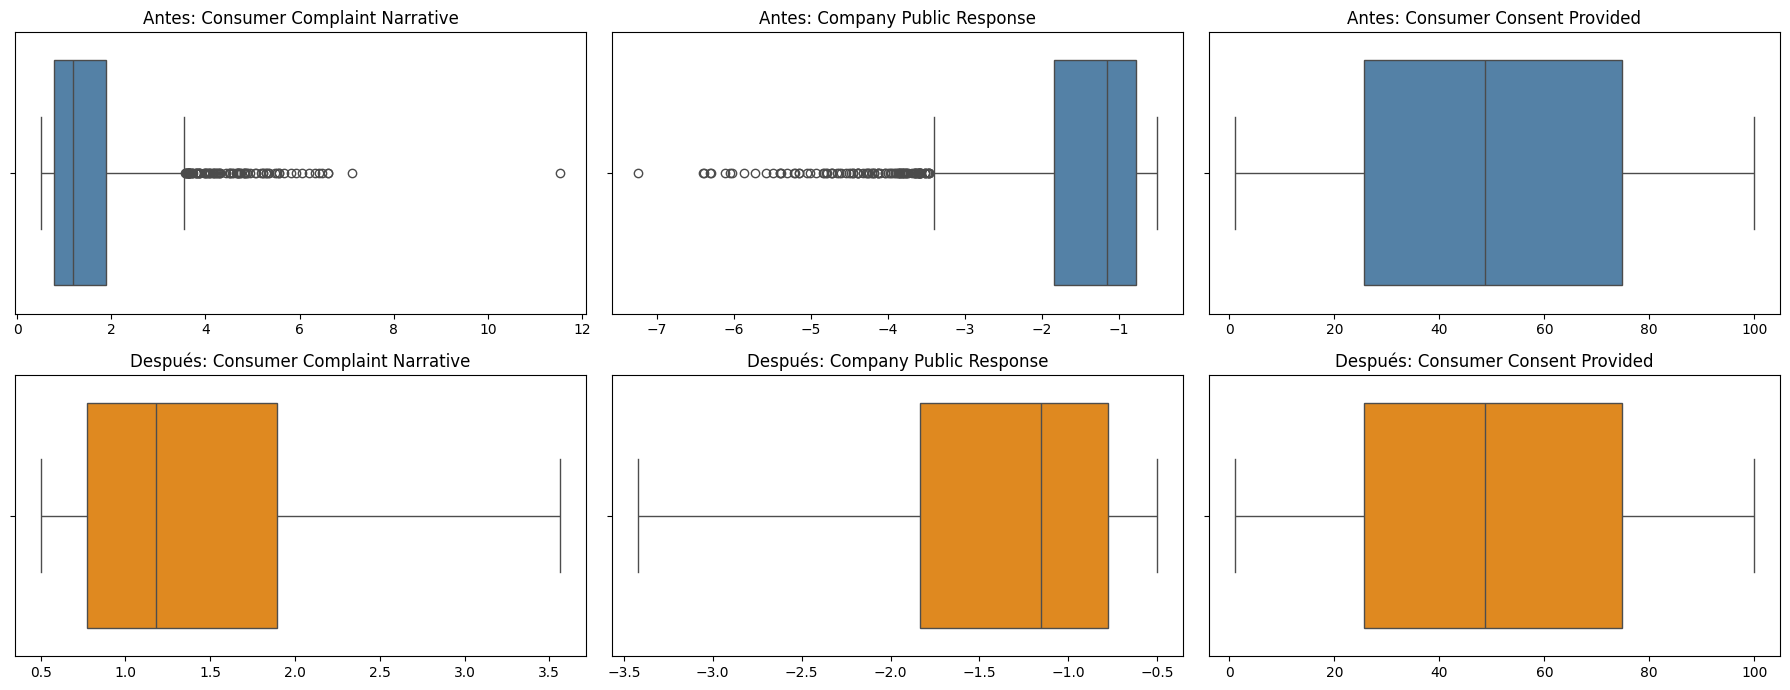

In [7]:
# 4.4 Atípicos: límites de Tukey y tratamiento
# Límites de Tukey: [Q1 - 1.5·IQR, Q3 + 1.5·IQR]. Se calculan para las 3 variables continuas
# (cols_continuas, definidas en el punto 3) sobre los datos ya limpios de 4.1–4.3.
def limites_tukey(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

tukey = []
for col in cols_continuas:
    s = df_limpio[col]
    li, ls = limites_tukey(s)
    tukey.append({
        "columna": col,
        "Q1": s.quantile(0.25), "Q3": s.quantile(0.75), "IQR": s.quantile(0.75) - s.quantile(0.25),
        "lim_inferior": li, "lim_superior": ls,
        "min": s.min(), "max": s.max(),
        "atipicos_bajo": int((s < li).sum()), "atipicos_alto": int((s > ls).sum()),
        "atipicos_%": round(((s < li) | (s > ls)).mean() * 100, 2),
    })
tukey = pd.DataFrame(tukey).set_index("columna")
print("Límites de Tukey y atípicos (antes del tratamiento):")
display(tukey.round(4))

# Tratamiento: winsorizar (recortar a los límites de Tukey) solo las variables con atípicos.
# Se conserva cada fila y se limita la influencia de los valores extremos.
cols_winsor = tukey.index[(tukey["atipicos_bajo"] + tukey["atipicos_alto"]) > 0].tolist()
print("Variables a winsorizar:", cols_winsor)

antes = df_limpio[cols_continuas].copy()
for col in cols_winsor:
    df_limpio[col] = df_limpio[col].clip(lower=tukey.loc[col, "lim_inferior"],
                                         upper=tukey.loc[col, "lim_superior"])

# Antes y después: resumen numérico
def resumen(d):
    return pd.DataFrame({
        "min": d.min(), "max": d.max(), "media": d.mean(), "mediana": d.median(),
        "desv_est": d.std(), "sesgo": d.skew(), "curtosis_fisher": d.kurt(),
    })
comparacion = pd.concat({"antes": resumen(antes), "después": resumen(df_limpio[cols_continuas])}, axis=1)
# Se reordena para ver cada estadístico con su antes y después lado a lado
comparacion = comparacion.swaplevel(axis=1)[resumen(antes).columns]
print("\nAntes vs. después:")
display(comparacion.round(4))

print("Atípicos restantes según los mismos límites:")
for col in cols_continuas:
    s = df_limpio[col]
    print(f"  {col}: {int(((s < tukey.loc[col, 'lim_inferior']) | (s > tukey.loc[col, 'lim_superior'])).sum())}")
print("Shape después de 4.4:", df_limpio.shape)

# Antes y después: boxplots
fig, axes = plt.subplots(2, len(cols_continuas), figsize=(18, 7))
for j, col in enumerate(cols_continuas):
    for i, (etiqueta, datos) in enumerate([("Antes", antes[col]), ("Después", df_limpio[col])]):
        sns.boxplot(x=datos, ax=axes[i, j], color="steelblue" if i == 0 else "darkorange")
        axes[i, j].set_title(f"{etiqueta}: {col}")
        axes[i, j].set_xlabel("")
plt.tight_layout()
plt.show()

**Justificación:**

Con los límites de Tukey (Q1 − 1.5·IQR, Q3 + 1.5·IQR), `Consumer Complaint Narrative` tiene 93 atípicos altos (4.68 %, por encima de 3.5643) y `Company Public Response` 104 atípicos bajos (5.23 %, por debajo de −3.4216), coherente con el sesgo y la curtosis vistos en el punto 3; `Consumer Consent Provided` no tiene atípicos y se conserva sin cambios. Se eligió **winsorizar** las dos primeras (recortar a los límites de Tukey) porque los atípicos son ~5 % de cada variable: filtrarlos eliminaría cerca de 200 filas, y no hay evidencia de que sean errores de registro, sino colas largas de la distribución. Así se conservan las 1989 filas y se reduce la influencia de los extremos: la curtosis baja de 8.2443 a 0.2248 y de 4.3878 a 0.2322, y el sesgo de 2.1751 a 1.0766 y de −1.8783 a −1.0821; las medianas no cambian. El sesgo residual (~±1.08) se tendrá en cuenta al normalizar en el punto 5.1.

### 4.5 Redundancia
Correlación entre las variables numéricas. ¿Hay columnas redundantes?

Columnas numéricas por almacenamiento en df_limpio: ['Consumer Complaint Narrative', 'Company Public Response', 'Zip Code', 'Consumer Consent Provided']
Columnas usadas en la correlación: ['Consumer Complaint Narrative', 'Company Public Response', 'Consumer Consent Provided']


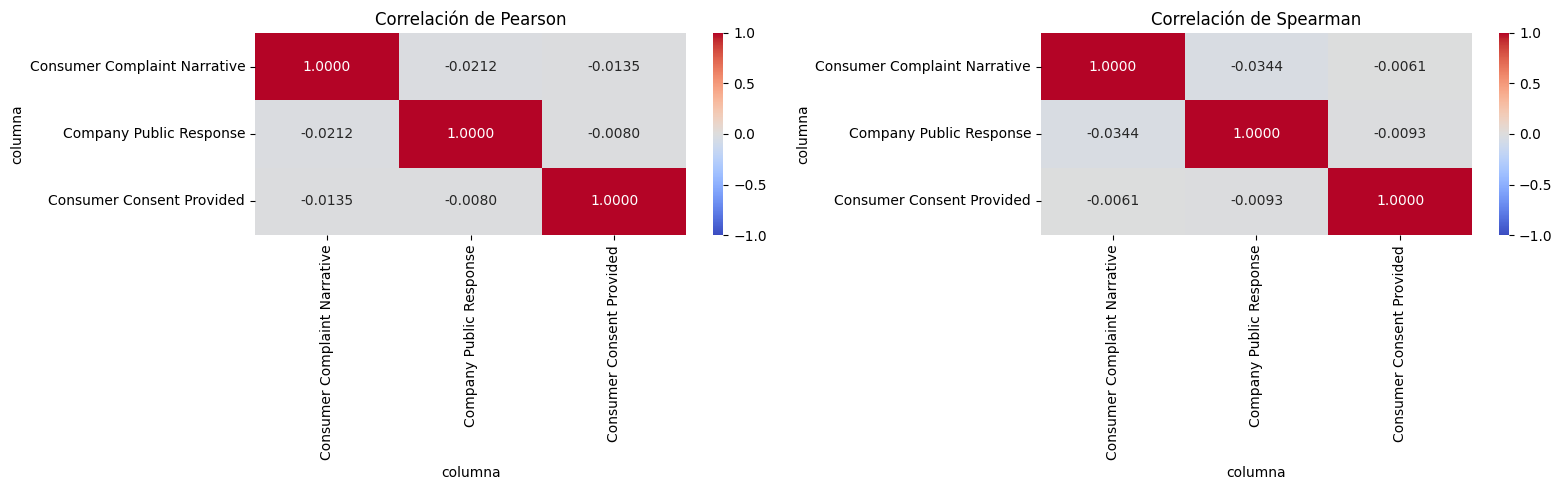

,variable_1,variable_2,pearson,spearman,redundante
0,Consumer Complaint Narrative,Company Public Response,-0.0212,-0.0344,False
1,Consumer Complaint Narrative,Consumer Consent Provided,-0.0135,-0.0061,False
2,Company Public Response,Consumer Consent Provided,-0.0080,-0.0093,False


Pares redundantes (|r| >= 0.8): 0

Zip Code -> State Name
Códigos postales distintos:                  1674
Códigos postales asociados a más de un estado: 3
Estados distintos:                            52


In [8]:
# 4.5 Redundancia: correlación entre las variables numéricas
# Se usan las variables numéricas conceptuales (las 3 continuas). Zip Code se excluye:
# aunque se almacena como número, es un código nominal (punto 2) y su correlación no tiene sentido.
print("Columnas numéricas por almacenamiento en df_limpio:",
      df_limpio.select_dtypes("number").columns.tolist())
print("Columnas usadas en la correlación:", cols_continuas)

# Pearson mide relación lineal; Spearman (por rangos) es robusta a la asimetría que aún
# tienen dos de las variables después de winsorizar (punto 4.4).
corr_pearson = df_limpio[cols_continuas].corr(method="pearson")
corr_spearman = df_limpio[cols_continuas].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (nombre, m) in zip(axes, [("Pearson", corr_pearson), ("Spearman", corr_spearman)]):
    sns.heatmap(m, annot=True, fmt=".4f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
    ax.set_title(f"Correlación de {nombre}")
plt.tight_layout()
plt.show()

# Pares de variables y criterio de redundancia: |r| >= 0.8 en alguna de las dos medidas
UMBRAL_REDUNDANCIA = 0.8
pares = []
for i, a in enumerate(cols_continuas):
    for b in cols_continuas[i + 1:]:
        pares.append({
            "variable_1": a, "variable_2": b,
            "pearson": corr_pearson.loc[a, b], "spearman": corr_spearman.loc[a, b],
        })
pares = pd.DataFrame(pares)
pares["redundante"] = (pares[["pearson", "spearman"]].abs() >= UMBRAL_REDUNDANCIA).any(axis=1)
display(pares.round(4))
print(f"Pares redundantes (|r| >= {UMBRAL_REDUNDANCIA}):", int(pares["redundante"].sum()))

# Redundancia complementaria entre Zip Code y State Name (no se ve con correlación porque
# son nominales): si cada código postal pertenece a un único estado, State Name se puede
# deducir de Zip Code y una de las dos sobra.
estados_por_zip = df_limpio.groupby("Zip Code")["State Name"].nunique()
print("\nZip Code -> State Name")
print("Códigos postales distintos:                 ", estados_por_zip.size)
print("Códigos postales asociados a más de un estado:", int((estados_por_zip > 1).sum()))
print("Estados distintos:                           ", df_limpio["State Name"].nunique())

**Conclusión:**

No hay columnas numéricas redundantes: entre las 3 variables continuas todas las correlaciones son prácticamente nulas, tanto de Pearson (entre −0.0212 y −0.0080) como de Spearman (entre −0.0344 y −0.0061), muy lejos del umbral |r| ≥ 0.8; cada una aporta información distinta y se conservan las tres. `Zip Code` se excluyó del análisis por ser nominal, pero se verificó su relación con `State Name`: de 1674 códigos postales, solo 3 aparecen asociados a más de un estado, así que el estado se deduce casi por completo del código postal y ambas columnas son redundantes entre sí. Se recomienda conservar `State Name` (52 categorías) y descartar `Zip Code` (1674 valores) al construir la vista minable.

## 5. Vista minable (15 pts · 20 min)
Objetivo del modelo: predecir `Consumer Disputed` (Yes / No).

### 5.1 Normalización
Al menos 2 variables con técnicas distintas. Justifica cada técnica según la forma de la distribución y verifica que sea aplicable a sus valores.

Shape de partida: (1989, 16)

Consumer Complaint Narrative: valores <= 0 -> 0 (mínimo = 0.5012)


Company Public Response: valores >= 0 -> 0 (máximo = -0.5007)
Parámetros del escalamiento robusto: mediana = -1.1562 | IQR = 1.0572


min     max   sesgo  \
Consumer Complaint Narrative antes              0.5012  3.5643  1.0766   
                             después (log)     -0.6908  1.2710  0.2762   
Company Public Response      antes             -3.4216 -0.5007 -1.0821   
                             después (robusto) -2.1428  0.6201 -1.0821   

                                                curtosis_fisher  
Consumer Complaint Narrative antes                       0.2248  
                             después (log)              -0.9630  
Company Public Response      antes                       0.2322  
                             después (robusto)           0.2322

Mediana e IQR de Company Public Response después del escalamiento: 0.0 | 1.0


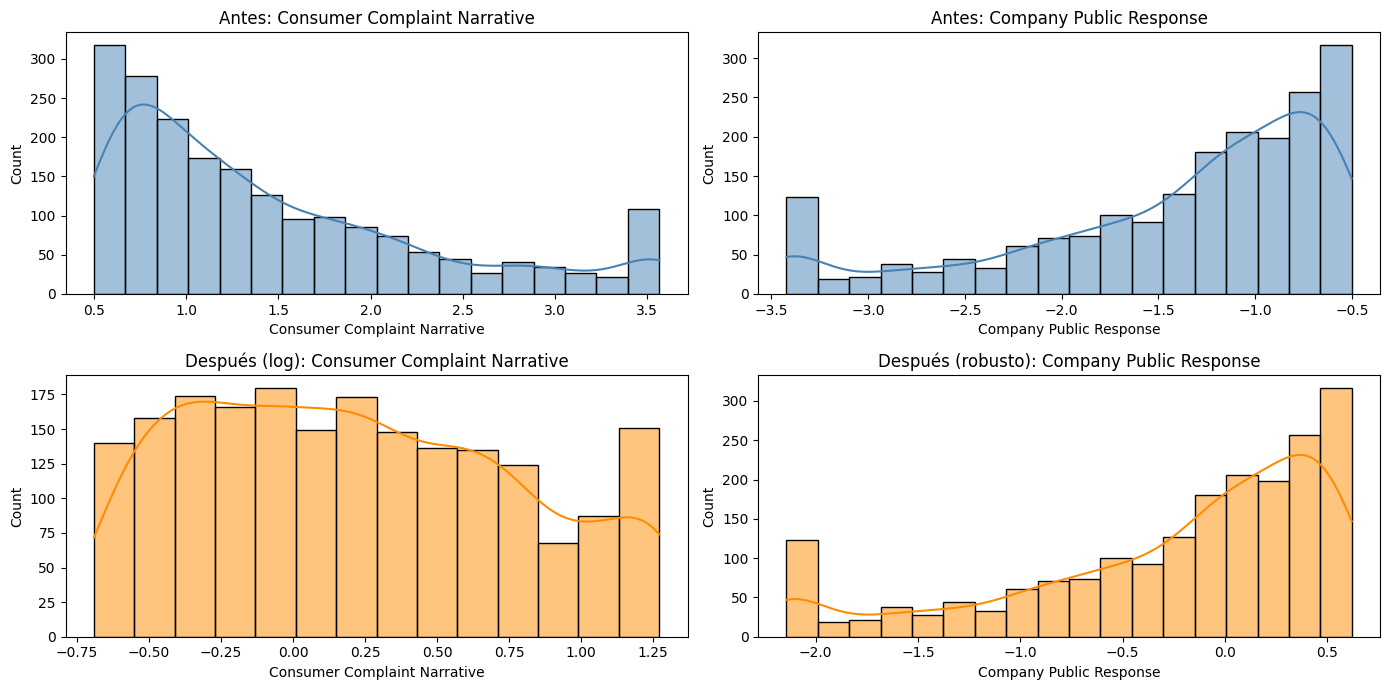

In [9]:
# 5.1 Normalización
# Se construye la vista minable sobre una copia del dataset limpio (salida del punto 4).
vista = df_limpio.copy()
print("Shape de partida:", vista.shape)

def forma(s):
    return {"min": s.min(), "max": s.max(), "sesgo": s.skew(), "curtosis_fisher": s.kurt()}

# --- a) Consumer Complaint Narrative -> transformación logarítmica ----------------------
# Sesgo positivo residual tras winsorizar (4.4). El log comprime la cola derecha, pero solo
# es aplicable si todos los valores son estrictamente positivos: se verifica antes.
col_log = "Consumer Complaint Narrative"
print(f"\n{col_log}: valores <= 0 -> {(vista[col_log] <= 0).sum()} (mínimo = {vista[col_log].min():.4f})")
assert (vista[col_log] > 0).all(), "El logaritmo no es aplicable: hay valores <= 0"
antes_log = vista[col_log].copy()
vista[col_log] = np.log(vista[col_log])

# --- b) Company Public Response -> escalamiento robusto (mediana e IQR) ------------------
# Todos sus valores son negativos (el log no es aplicable) y conserva sesgo negativo, así
# que se centra en la mediana y se escala por el IQR, que no dependen de los extremos.
col_rob = "Company Public Response"
print(f"{col_rob}: valores >= 0 -> {(vista[col_rob] >= 0).sum()} (máximo = {vista[col_rob].max():.4f})")
mediana_rob = vista[col_rob].median()
iqr_rob = vista[col_rob].quantile(0.75) - vista[col_rob].quantile(0.25)
print(f"Parámetros del escalamiento robusto: mediana = {mediana_rob:.4f} | IQR = {iqr_rob:.4f}")
assert iqr_rob > 0, "El escalamiento robusto no es aplicable: IQR = 0"
antes_rob = vista[col_rob].copy()
vista[col_rob] = (vista[col_rob] - mediana_rob) / iqr_rob

# --- Antes vs. después ---------------------------------------------------------------------
norm = pd.DataFrame({
    (col_log, "antes"): forma(antes_log), (col_log, "después (log)"): forma(vista[col_log]),
    (col_rob, "antes"): forma(antes_rob), (col_rob, "después (robusto)"): forma(vista[col_rob]),
}).T
display(norm.round(4))
print("Mediana e IQR de Company Public Response después del escalamiento:",
      round(vista[col_rob].median(), 4), "|",
      round(vista[col_rob].quantile(0.75) - vista[col_rob].quantile(0.25), 4))

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for j, (col, a, etiqueta) in enumerate([(col_log, antes_log, "log"), (col_rob, antes_rob, "robusto")]):
    sns.histplot(a, kde=True, ax=axes[0, j], color="steelblue")
    axes[0, j].set_title(f"Antes: {col}")
    sns.histplot(vista[col], kde=True, ax=axes[1, j], color="darkorange")
    axes[1, j].set_title(f"Después ({etiqueta}): {col}")
plt.tight_layout()
plt.show()

**Justificación:**

- **`Consumer Complaint Narrative` → transformación logarítmica.** Después de winsorizar (4.4) conserva sesgo positivo (1.0766): cola a la derecha con valores acumulados cerca del mínimo. El logaritmo comprime esa cola y lleva el sesgo a 0.2762. Es aplicable porque todos sus valores son estrictamente positivos (0 valores ≤ 0; mínimo 0.5012).
- **`Company Public Response` → escalamiento robusto** ((x − mediana) / IQR, con mediana −1.1562 e IQR 1.0572). Todos sus valores son negativos (máximo −0.5007), así que el logaritmo no es aplicable, y mantiene sesgo negativo (−1.0821). La media y la desviación estándar (z-score) se ven afectadas por la asimetría, mientras que la mediana y el IQR no; por eso es más adecuado que min-max o z-score. Es aplicable porque el IQR es mayor que 0. Tras el ajuste la variable queda con mediana 0 e IQR 1; como es una transformación lineal, la forma no cambia (sesgo y curtosis iguales), solo la escala.
- `Consumer Consent Provided` no se normaliza porque se discretiza en 5.2.

*Nota:* los parámetros (mediana e IQR) se calcularon con todo el dataset porque el enunciado separa train/test en 5.4. En un flujo de modelado se calcularían solo con el train para evitar fuga de información; el logaritmo no tiene ese problema porque se aplica fila por fila.

### 5.2 Discretización
Al menos 1 variable. Elige el número de bins con un criterio (Sturges, Freedman-Diaconis, Scott o cuantiles) y justifícalo.

In [10]:
# 5.2 Discretización de Consumer Consent Provided
# Variable casi uniforme (sesgo 0.04, curtosis -1.16) y sin atípicos (4.4): con intervalos de
# igual ancho cada bin recibe una cantidad parecida de registros.
col_disc = "Consumer Consent Provided"
s = vista[col_disc]
n = len(s)
rango = s.max() - s.min()
iqr = s.quantile(0.75) - s.quantile(0.25)

# Número de bins según tres criterios
ancho_fd = 2 * iqr / n ** (1 / 3)             # Freedman-Diaconis
ancho_scott = 3.49 * s.std() / n ** (1 / 3)   # Scott
bins_sturges = int(np.ceil(1 + np.log2(n)))   # Sturges
criterios = pd.DataFrame({
    "ancho_bin": [rango / bins_sturges, ancho_fd, ancho_scott],
    "bins": [bins_sturges, int(np.ceil(rango / ancho_fd)), int(np.ceil(rango / ancho_scott))],
}, index=["Sturges", "Freedman-Diaconis", "Scott"])
print(f"n = {n} | rango = {rango:.4f} | IQR = {iqr:.4f}")
display(criterios.round(4))

# Se elige Freedman-Diaconis (usa el IQR, robusto) y se discretiza en intervalos de igual
# ancho. labels=False devuelve el número de intervalo (0, 1, ..., k-1), que es una variable
# ordinal que respeta el orden de los valores originales.
n_bins = criterios.loc["Freedman-Diaconis", "bins"]
intervalos = pd.cut(s, bins=n_bins)
vista["Consent Provided Bin"] = pd.cut(s, bins=n_bins, labels=False)

tabla_bins = (pd.DataFrame({"intervalo": intervalos, "bin": vista["Consent Provided Bin"]})
              .groupby(["bin", "intervalo"], observed=True).size().rename("registros").reset_index())
display(tabla_bins)
print(f"Registros por bin: mín = {tabla_bins['registros'].min()} | máx = {tabla_bins['registros'].max()}")

# Se reemplaza la variable continua por su versión discretizada
vista = vista.drop(columns=col_disc)
print("Shape después de 5.2:", vista.shape)

n = 1989 | rango = 98.9501 | IQR = 49.1955


,ancho_bin,bins
Sturges,8.2458,12
Freedman-Diaconis,7.8237,13
Scott,7.8986,13


,bin,intervalo,registros
0,0,"(0.907, 8.617]",160
1,1,"(8.617, 16.229]",151
2,2,"(16.229, 23.841]",161
3,3,"(23.841, 31.452]",132
4,4,"(31.452, 39.064]",164
5,5,"(39.064, 46.675]",174
6,6,"(46.675, 54.287]",167
7,7,"(54.287, 61.898]",156
8,8,"(61.898, 69.51]",137
9,9,"(69.51, 77.121]",147


Registros por bin: mín = 132 | máx = 174
Shape después de 5.2: (1989, 16)


**Justificación:**

Se discretizó `Consumer Consent Provided` porque su distribución es casi uniforme (sesgo 0.0365, curtosis −1.1564 en el punto 3) y no tiene atípicos (4.4), así que intervalos de igual ancho reparten los registros de forma equilibrada. Los tres criterios dan resultados similares: Sturges 12 bins, Freedman-Diaconis 13 y Scott 13. Se eligió **Freedman-Diaconis (13 bins, ancho 7.8237)** porque calcula el ancho a partir del IQR, que es robusto, y coincide con Scott, mientras que Sturges supone normalidad, lo que no se cumple aquí. El resultado confirma la elección: cada bin tiene entre 132 y 174 registros. La nueva columna `Consent Provided Bin` toma valores de 0 a 12 y es **ordinal**: el número de intervalo respeta el orden de los valores originales. Reemplaza a la variable continua.

### 5.3 Numerización
Una nominal de baja cardinalidad con One-Hot y `Company` (alta cardinalidad) con una estrategia adecuada. Si creas una ordinal, respeta su orden.

In [11]:
# 5.3 Numerización
# --- a) One-Hot para nominales de baja cardinalidad ----------------------------------------
cols_onehot = ["Product Name", "Submitted via", "Company Response to Consumer"]
print("Categorías por variable One-Hot:", vista[cols_onehot].nunique().to_dict())
vista = pd.get_dummies(vista, columns=cols_onehot, prefix=cols_onehot, dtype=int)

# --- b) Frequency encoding para nominales de alta cardinalidad -----------------------------
# Company (218 categorías) y las demás de alta cardinalidad. One-Hot crearía cientos de
# columnas casi vacías, y target encoding usaría el objetivo (riesgo de fuga de información).
# Cada categoría se reemplaza por su proporción de registros en el dataset.
cols_freq = ["Company", "State Name", "Issue", "Sub Product", "Sub Issue"]
print("Categorías por variable con frequency encoding:", vista[cols_freq].nunique().to_dict())
for col in cols_freq:
    vista[col] = vista[col].map(vista[col].value_counts(normalize=True))
display(vista[cols_freq].describe().loc[["min", "max", "mean"]].round(4))

# --- c) Fechas -> variable numérica derivada ------------------------------------------------
# Días entre la recepción de la queja y su envío a la empresa (ya sin inconsistencias, 4.3).
vista["Dias Envio"] = (vista["Date Sent to Company"] - vista["Date Received"]).dt.days
print("\nDias Envio:", vista["Dias Envio"].describe()[["min", "50%", "max"]].to_dict())

# --- d) Columnas que no pasan a la vista -----------------------------------------------------
print("Timely Response:", vista["Timely Response"].value_counts().to_dict())
cols_fuera = ["Date Received", "Date Sent to Company", "Zip Code", "Timely Response"]
vista = vista.drop(columns=cols_fuera)
print("Columnas eliminadas:", cols_fuera)

# Verificación: todo numérico salvo el objetivo, y sin nulos
no_numericas = vista.drop(columns="Consumer Disputed").select_dtypes(exclude="number").columns.tolist()
print("\nColumnas no numéricas (sin contar el objetivo):", no_numericas)
print("Nulos totales:", int(vista.isna().sum().sum()))
print("Shape después de 5.3:", vista.shape)
print("Columnas:", vista.columns.tolist())

Categorías por variable One-Hot: {'Product Name': 8, 'Submitted via': 5, 'Company Response to Consumer': 4}
Categorías por variable con frequency encoding: {'Company': 218, 'State Name': 52, 'Issue': 63, 'Sub Product': 26, 'Sub Issue': 46}


,Company,State Name,Issue,Sub Product,Sub Issue
min,0.0005,0.0005,0.0005,0.0010,0.0005
max,0.1443,0.1684,0.2745,0.2423,0.7285
mean,0.0523,0.0617,0.1062,0.1335,0.5350



Dias Envio: {'min': 0.0, '50%': 2.0, 'max': 292.0}
Timely Response: {'Yes': 1982, 'No': 7}
Columnas eliminadas: ['Date Received', 'Date Sent to Company', 'Zip Code', 'Timely Response']

Columnas no numéricas (sin contar el objetivo): []
Nulos totales: 0
Shape después de 5.3: (1989, 27)
Columnas: ['Sub Product', 'Issue', 'Sub Issue', 'Consumer Complaint Narrative', 'Company Public Response', 'Company', 'State Name', 'Consumer Disputed', 'Consent Provided Bin', 'Product Name_Bank account or service', 'Product Name_Consumer Loan', 'Product Name_Credit card', 'Product Name_Credit reporting', 'Product Name_Debt collection', 'Product Name_Money transfers', 'Product Name_Mortgage', 'Product Name_Student loan', 'Submitted via_Fax', 'Submitted via_Phone', 'Submitted via_Postal mail', 'Submitted via_Referral', 'Submitted via_Web', 'Company Response to Consumer_Closed', 'Company Response to Consumer_Closed with explanation', 'Company Response to Consumer_Closed with monetary relief', 'Company Re

**Justificación:**

- **One-Hot** para las nominales de baja cardinalidad: `Product Name` (8 categorías), `Submitted via` (5) y `Company Response to Consumer` (4). Son pocas categorías sin orden natural, así que One-Hot no impone un orden falso y solo agrega 17 columnas binarias.
- **`Company` (218 categorías) → frequency encoding**: cada empresa se reemplaza por su proporción de quejas en el dataset (entre 0.0005 y 0.1443). One-Hot crearía 218 columnas casi vacías, y target encoding usaría el objetivo `Consumer Disputed`, con riesgo de fuga de información. La frecuencia conserva una señal útil (el tamaño de la empresa en el volumen de quejas) en una sola columna. Con el mismo criterio se codificaron `State Name` (52), `Issue` (63), `Sub Product` (26) y `Sub Issue` (46).
- **Ordinal**: `Consent Provided Bin` (5.2) ya es numérica y respeta el orden de los intervalos (0–12).
- **Fechas**: se reemplazaron por `Dias Envio` (días entre recepción y envío; mínimo 0, mediana 2, máximo 292), que resume la información útil de ambas fechas en una variable numérica.
- **Columnas descartadas**: `Zip Code`, redundante con `State Name` (4.5); `Timely Response`, casi constante (1982 *Yes* y 7 *No*, 4.2); y las dos fechas originales, ya representadas por `Dias Envio`.

Resultado: (1989, 27), sin columnas no numéricas (salvo el objetivo, que se convierte en 5.4) y con 0 nulos.

### 5.4 Objetivo y balanceo
Convierte el objetivo a 0/1, separa train y test y, si está desbalanceado, balancea solo el train. Muestra los conteos antes y después.

In [12]:
# 5.4 Objetivo y balanceo
from sklearn.model_selection import train_test_split
from sklearn.utils import resample

# Objetivo a 0/1 (Yes = 1: el consumidor disputó la respuesta)
vista["Consumer Disputed"] = vista["Consumer Disputed"].map({"No": 0, "Yes": 1})
assert vista["Consumer Disputed"].notna().all(), "Hay valores del objetivo sin mapear"
print("Distribución del objetivo (dataset completo):")
display(pd.DataFrame({
    "registros": vista["Consumer Disputed"].value_counts(),
    "%": (vista["Consumer Disputed"].value_counts(normalize=True) * 100).round(2),
}))

X = vista.drop(columns="Consumer Disputed")
y = vista["Consumer Disputed"]

# Partición 80/20 estratificada: train y test conservan la misma proporción de clases.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

def conteo(y_):
    return {"0 (No)": int((y_ == 0).sum()), "1 (Yes)": int((y_ == 1).sum()),
            "% clase 1": round((y_ == 1).mean() * 100, 2), "total": len(y_)}

# Balanceo solo del train: sobremuestreo aleatorio de la clase minoritaria hasta igualar
# a la mayoritaria. El test no se toca para que refleje la distribución real.
train = pd.concat([X_train, y_train], axis=1)
mayoritaria = train[train["Consumer Disputed"] == 0]
minoritaria = train[train["Consumer Disputed"] == 1]
minoritaria_sobre = resample(minoritaria, replace=True, n_samples=len(mayoritaria), random_state=42)
train_bal = pd.concat([mayoritaria, minoritaria_sobre]).sample(frac=1, random_state=42)
X_train_bal = train_bal.drop(columns="Consumer Disputed")
y_train_bal = train_bal["Consumer Disputed"]

print("Conteos antes y después del balanceo:")
display(pd.DataFrame.from_dict({"train (antes)": conteo(y_train), "train (después)": conteo(y_train_bal),
                                "test (sin cambios)": conteo(y_test)}, orient="index"))
print("Shapes -> X_train_bal:", X_train_bal.shape, "| X_test:", X_test.shape)

Distribución del objetivo (dataset completo):


,registros,%
Consumer Disputed,,
0,1542,77.53
1,447,22.47


Conteos antes y después del balanceo:


,0 (No),1 (Yes),% clase 1,total
train (antes),1233,358,22.50,1591
train (después),1233,1233,50.00,2466
test (sin cambios),309,89,22.36,398


Shapes -> X_train_bal: (2466, 26) | X_test: (398, 26)


**Justificación:**

El objetivo se convirtió a 0/1 (*No* = 0, *Yes* = 1). Está desbalanceado: 1542 (77.53 %) frente a 447 (22.47 %). Se separó en train y test (80/20) **estratificando por el objetivo**, de modo que ambos conservan la proporción original (22.50 % y 22.36 % de clase 1). Se balanceó **solo el train** con sobremuestreo aleatorio de la clase minoritaria (de 358 a 1233 registros, 50 % por clase; train de 1591 a 2466 filas). El test queda intacto (309 / 89) para evaluar el modelo con la distribución real. Se usó sobremuestreo y no submuestreo para no descartar 875 registros de la clase mayoritaria; se implementó con `sklearn.utils.resample` porque `imbalanced-learn` (SMOTE) no está instalado en el entorno.

## 6. Entrega
1. Exporta `vista_minable_parcial.csv`: columnas numéricas y sin nulos. Imprime su `shape`.

> La bitácora `BITACORA.md` vale 5 puntos adicionales.

In [13]:
# 6.1 Exportación de la vista minable
# Se exporta la vista completa (todas las filas, con el objetivo ya en 0/1), antes de la
# partición train/test y del balanceo, para que el archivo conserve la distribución real.
# Se guarda en data/ junto al archivo original.
RUTA_VISTA = "data/vista_minable_parcial.csv"

# Verificaciones exigidas por el enunciado: columnas numéricas y sin nulos
no_numericas = vista.select_dtypes(exclude="number").columns.tolist()
nulos = int(vista.isna().sum().sum())
print("Columnas no numéricas:", no_numericas)
print("Nulos totales:", nulos)
assert not no_numericas and nulos == 0, "La vista minable no cumple: hay columnas no numéricas o nulos"

vista.to_csv(RUTA_VISTA, index=False)

# Se relee el archivo exportado para confirmar que quedó bien escrito
vista_exportada = pd.read_csv(RUTA_VISTA)
print("\nArchivo exportado:", RUTA_VISTA)
print("Shape:", vista_exportada.shape)
print("Distribución del objetivo en el archivo:", vista_exportada["Consumer Disputed"].value_counts().to_dict())

Columnas no numéricas: []
Nulos totales: 0

Archivo exportado: data/vista_minable_parcial.csv
Shape: (1989, 27)
Distribución del objetivo en el archivo: {0: 1542, 1: 447}
